# Prepoznavanje zdravstvenog stanja pčela sa fotografije
### KORAK 4: Evaluacija i poređenje tri arhitekture

Test skup: **3.408 slika iz 2 snimka koje modeli nikad nisu videli** (942 zaražene, 2.466 zdravih).
Metrike koje je tražila profesorica: **tačnost, preciznost, odziv (recall), F1 i matrica konfuzije**.

## 1. Uvoz biblioteka

In [1]:
import sys, os, json, ast, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw

# src.evaluate pri importu prebacuje matplotlib u "Agg" (bez prikaza) — zato se
# učitava ovde, pa se prikaz u notebook-u vraća sa %matplotlib inline
import src.evaluate, src.model_checks
%matplotlib inline

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 60)

GRAFICI = ROOT / "grafici"; GRAFICI.mkdir(exist_ok=True)
RUNS = ROOT / "runs"

# Iste boje u svim graficima
BOJA_KLASE = {"zdrava": "#2ecc71", "varoa": "#e74c3c"}
BOJA_MODELA = {"MobileNetV3-Large": "#3498db", "ResNet50": "#9b59b6", "EfficientNetB0": "#f39c12"}
MODELI = ["MobileNetV3-Large", "ResNet50", "EfficientNetB0"]
RUN_ZA = {"MobileNetV3-Large": "varroa_mobilenet_v3_large", "ResNet50": "varroa_resnet50",
          "EfficientNetB0": "varroa_efficientnet_b0"}

def sacuvaj(ime):
    """Čuva trenutni grafik u grafici/<ime>.png (isti grafici idu u prezentaciju)."""
    plt.savefig(GRAFICI / f"{ime}.png", dpi=150, bbox_inches="tight")

def oznaci_stubice(ax, fmt="{:.3f}", rot=0, size=9):
    for p in ax.patches:
        h = p.get_height()
        if np.isfinite(h) and h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h), ha="center",
                        va="bottom", fontsize=size, rotation=rot, xytext=(0, 2), textcoords="offset points")

print("Biblioteke uspešno učitane. Koren projekta:", ROOT)

Biblioteke uspešno učitane. Koren projekta: /Users/medzidjasarovic/Kosnica_IS/KosnicaML


## 2. Predikcije modela na test skupu

In [2]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)
from src.predictions import predictions
pred = {m: predictions(RUN_ZA[m], "test") for m in MODELI}
print({m: len(p) for m, p in pred.items()})

{'MobileNetV3-Large': 3408, 'ResNet50': 3408, 'EfficientNetB0': 3408}


## 3. Tabela rezultata

In [3]:
rez = []
for m, p in pred.items():
    y, yp = p["true"], p["pred"]
    rez.append({"Model": m, "Tačnost": accuracy_score(y, yp),
                "Preciznost": precision_score(y, yp, average="macro"), "Odziv": recall_score(y, yp, average="macro"),
                "F1": f1_score(y, yp, average="macro"), "Odziv (varoa)": recall_score(y, yp),
                "Preciznost (varoa)": precision_score(y, yp), "ROC AUC": roc_auc_score(y, p["p_varoa"])})
rez = pd.DataFrame(rez).set_index("Model").sort_values("F1", ascending=False)
print("VARROADATASET — TEST SKUP (sortirano po F1)"); print("=" * 55)
rez.round(4)

VARROADATASET — TEST SKUP (sortirano po F1)


,Tačnost,Preciznost,Odziv,F1,Odziv (varoa),Preciznost (varoa),ROC AUC
Model,,,,,,,
ResNet50,0.9310,0.9152,0.9117,0.9134,0.8684,0.8805,0.9753
MobileNetV3-Large,0.9199,0.8964,0.9063,0.9011,0.8758,0.8410,0.9662
EfficientNetB0,0.9217,0.9054,0.8970,0.9011,0.8418,0.8705,0.9644


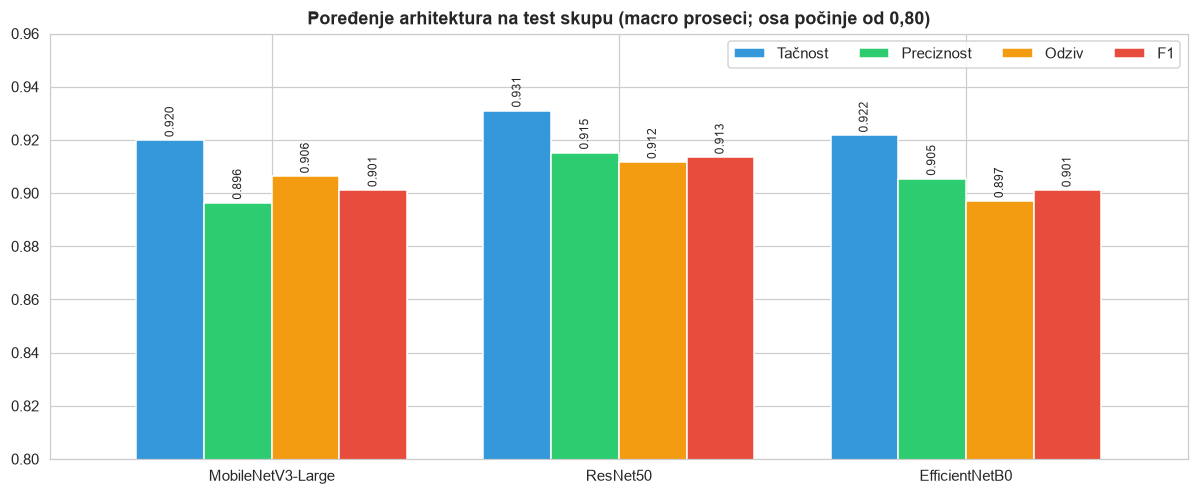

In [4]:
ax = rez.loc[MODELI, ["Tačnost", "Preciznost", "Odziv", "F1"]].plot(kind="bar", figsize=(11, 4.6), rot=0, width=0.78,
                                                                   color=["#3498db", "#2ecc71", "#f39c12", "#e74c3c"])
ax.set_ylim(0.8, 0.96); oznaci_stubice(ax, "{:.3f}", rot=90, size=8); ax.set_xlabel("")
ax.set_title("Poređenje arhitektura na test skupu (macro proseci; osa počinje od 0,80)"); ax.legend(loc="upper right", ncol=4)
plt.tight_layout(); sacuvaj("04a_poredjenje_metrika"); plt.show()

## 4. Matrice konfuzije

Red = stvarna klasa, kolona = odluka modela. Najskuplja greška za pčelara je **propuštena zaraza**
(donji levi kvadrat); gornji desni su **lažne uzbune**.

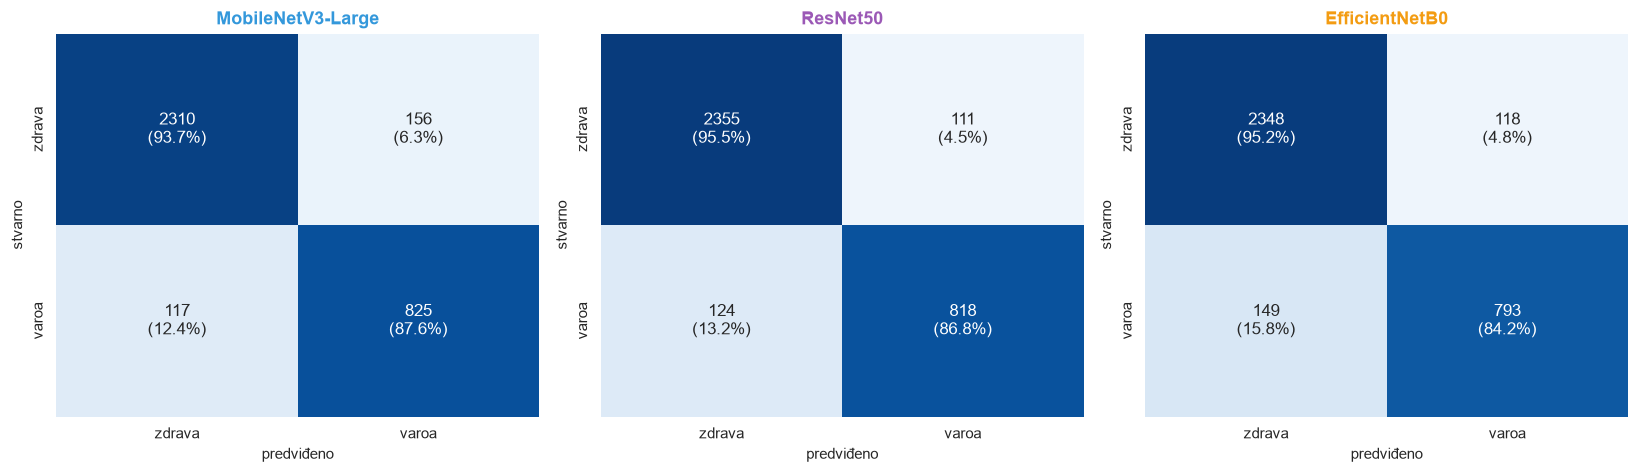

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, m in zip(axes, MODELI):
    cm = confusion_matrix(pred[m]["true"], pred[m]["pred"]); pc = cm / cm.sum(axis=1, keepdims=True)
    ann = np.array([[f"{cm[i, j]}\n({pc[i, j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(pc, annot=ann, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["zdrava", "varoa"], yticklabels=["zdrava", "varoa"], annot_kws={"size": 11})
    ax.set_title(m, color=BOJA_MODELA[m]); ax.set_xlabel("predviđeno"); ax.set_ylabel("stvarno")
plt.tight_layout(); sacuvaj("04b_matrice_konfuzije"); plt.show()

## 5. ROC krive

ROC kriva pokazuje odnos otkrivenih zaraza i lažnih uzbuna za **svaki mogući prag** odluke (ne samo 0,5).
Površina ispod krive (AUC) je 1,0 za savršen model i 0,5 za nasumično pogađanje.

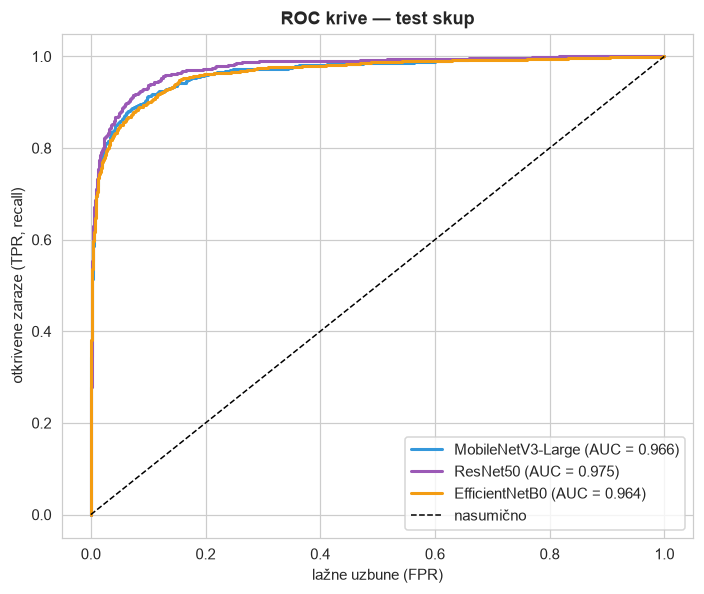

In [6]:
plt.figure(figsize=(6.5, 5.5))
for m in MODELI:
    fpr, tpr, _ = roc_curve(pred[m]["true"], pred[m]["p_varoa"])
    plt.plot(fpr, tpr, color=BOJA_MODELA[m], lw=2, label=f"{m} (AUC = {roc_auc_score(pred[m]['true'], pred[m]['p_varoa']):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="nasumično")
plt.xlabel("lažne uzbune (FPR)"); plt.ylabel("otkrivene zaraze (TPR, recall)")
plt.title("ROC krive — test skup"); plt.legend(loc="lower right")
plt.tight_layout(); sacuvaj("04c_roc_krive"); plt.show()

## 6. Rezultat po test snimku i po vidljivosti grinje

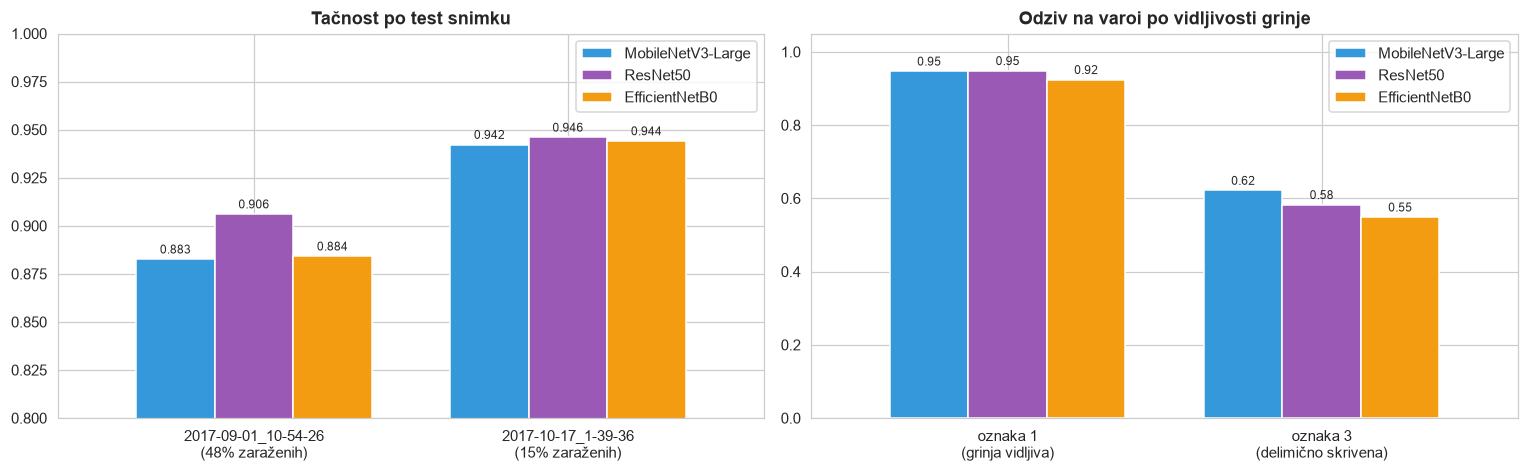

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
po_snimku = pd.DataFrame({m: pred[m].groupby("video").apply(lambda g: (g["true"] == g["pred"]).mean()) for m in MODELI})
udeo = pred[MODELI[0]].groupby("video")["true"].mean()
po_snimku.index = [f"{v}\n({u:.0%} zaraženih)" for v, u in zip(po_snimku.index, udeo)]
po_snimku.plot(kind="bar", ax=axes[0], rot=0, color=[BOJA_MODELA[m] for m in MODELI], width=0.75)
axes[0].set_ylim(0.8, 1); oznaci_stubice(axes[0], "{:.3f}", size=8); axes[0].set_title("Tačnost po test snimku")

po_oznaci = pd.DataFrame({m: pred[m][pred[m]["true"] == 1].groupby("raw_label")["pred"].mean() for m in MODELI})
po_oznaci.index = ["oznaka 1\n(grinja vidljiva)", "oznaka 3\n(delimično skrivena)"]
po_oznaci.plot(kind="bar", ax=axes[1], rot=0, color=[BOJA_MODELA[m] for m in MODELI], width=0.75)
axes[1].set_ylim(0, 1.05); oznaci_stubice(axes[1], "{:.2f}", size=8); axes[1].set_title("Odziv na varoi po vidljivosti grinje")
plt.tight_layout(); sacuvaj("04d_po_snimku_i_oznaci"); plt.show()

**Zaključak:** rezultat je ujednačen na oba test snimka — modeli ne zavise od uslova jednog snimka.
Kada je grinja jasno vidljiva (oznaka 1), sva tri modela je pronalaze u ~93–95% slučajeva; kada je
delimično skrivena (oznaka 3), u ~55–62% — tu leži najveći deo propuštenih zaraza.

## 7. Analiza grešaka — ResNet50

*Gde model najviše greši i zašto?*

Propuštene zaraze (FN): 124 od 942  —  od toga oznaka 3 (skrivena grinja): 86
Lažne uzbune (FP):      111 od 2466


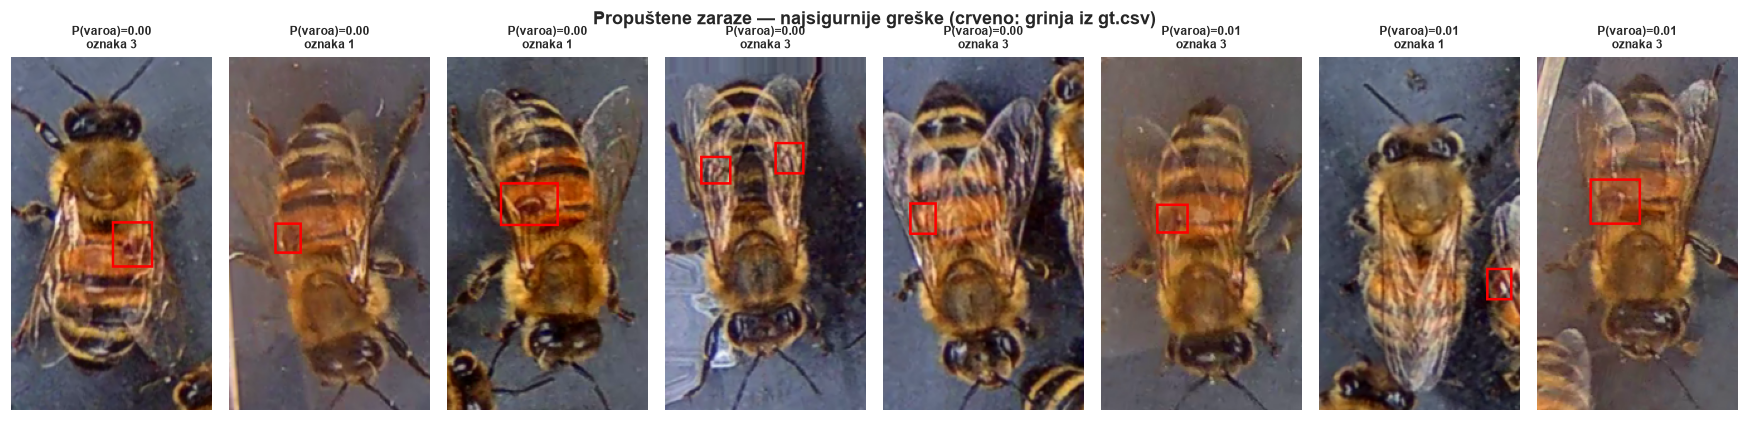

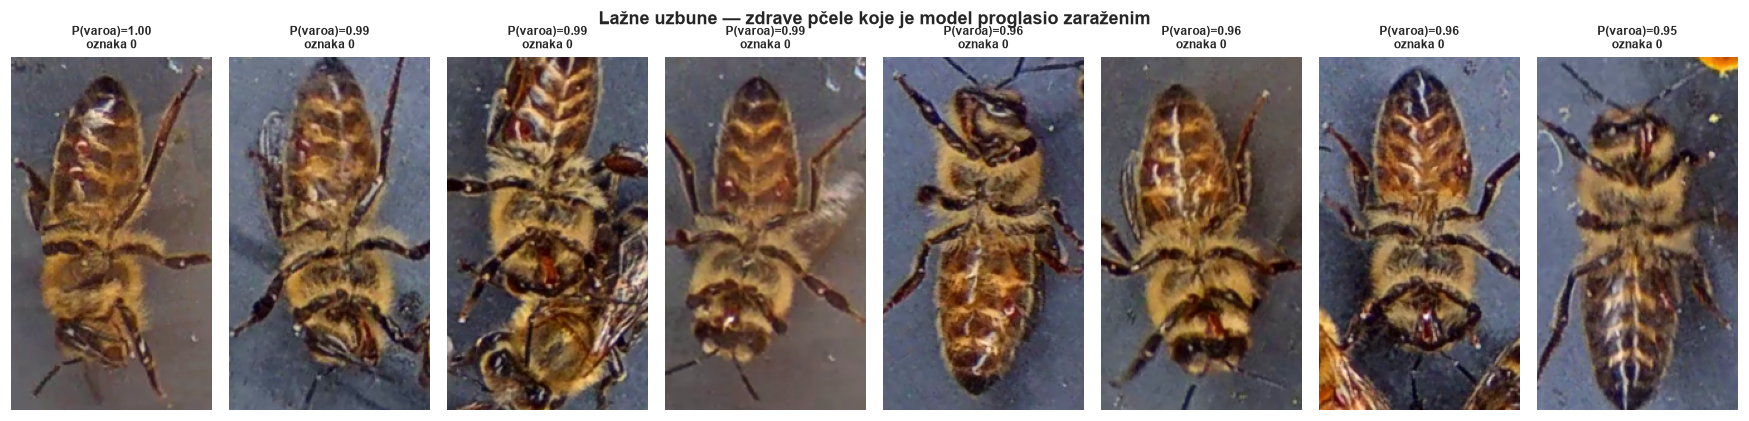

In [8]:
p = pred["ResNet50"].copy()
p["boxes"] = p["boxes"].apply(ast.literal_eval)
fn = p[(p["true"] == 1) & (p["pred"] == 0)]; fp = p[(p["true"] == 0) & (p["pred"] == 1)]
print(f"Propuštene zaraze (FN): {len(fn)} od {int(p['true'].sum())}  —  od toga oznaka 3 (skrivena grinja): {int((fn['raw_label'] == 3).sum())}")
print(f"Lažne uzbune (FP):      {len(fp)} od {int((p['true'] == 0).sum())}")

def mreza(frame, naslov, ime, n=8):
    uz = frame.sort_values("p_varoa", ascending=naslov.startswith("Propuštene")).head(n)
    fig, axes = plt.subplots(1, n, figsize=(16, 3.9))
    for ax, (_, r) in zip(axes, uz.iterrows()):
        im = Image.open(r["path"]).convert("RGB"); d = ImageDraw.Draw(im)
        for b in r["boxes"]: d.rectangle(b, outline=(255, 0, 0), width=2)
        ax.imshow(im); ax.axis("off"); ax.set_title(f"P(varoa)={r['p_varoa']:.2f}\noznaka {r['raw_label']}", fontsize=8)
    fig.suptitle(naslov, fontweight="bold"); plt.tight_layout(); sacuvaj(ime); plt.show()

mreza(fn, "Propuštene zaraze — najsigurnije greške (crveno: grinja iz gt.csv)", "04e_greske_propustene")
mreza(fp, "Lažne uzbune — zdrave pčele koje je model proglasio zaraženim", "04f_greske_lazne_uzbune")

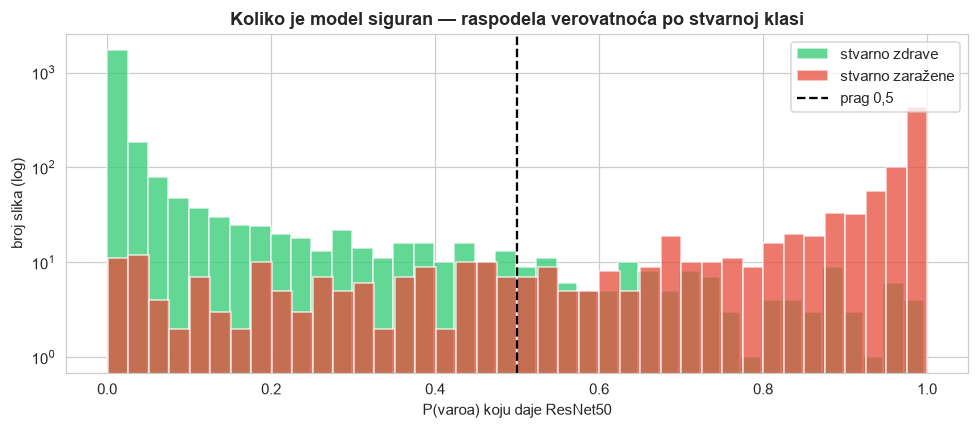

In [9]:
plt.figure(figsize=(9, 4))
plt.hist(p[p["true"] == 0]["p_varoa"], bins=40, alpha=0.75, color=BOJA_KLASE["zdrava"], label="stvarno zdrave")
plt.hist(p[p["true"] == 1]["p_varoa"], bins=40, alpha=0.75, color=BOJA_KLASE["varoa"], label="stvarno zaražene")
plt.axvline(0.5, color="k", ls="--", label="prag 0,5"); plt.yscale("log")
plt.xlabel("P(varoa) koju daje ResNet50"); plt.ylabel("broj slika (log)"); plt.legend()
plt.title("Koliko je model siguran — raspodela verovatnoća po stvarnoj klasi")
plt.tight_layout(); sacuvaj("04g_raspodela_verovatnoca"); plt.show()

## 8. Zaključak KORAKA 4

- **ResNet50** je najbolji po svim agregatnim metrikama (tačnost 0,931, F1 0,913, AUC 0,975) i ima
  najmanje lažnih uzbuna.
- **MobileNetV3** ima najveći odziv na varoi (0,876), uz više lažnih uzbuna.
- Razlike između arhitektura su ~1 procentni poen — svaka je trenirana jednom, pa ih ne treba precenjivati.
- Najveći izvor grešaka su **delimično skrivene grinje** (oznaka 3) i odsjaji/tamna mesta koja liče na grinju.

Da li modeli zaista gledaju grinju — KORAK 5.